**5.1 Tugas 1 — Hitung Manual**

**5.2	Tugas 2 — Verifikasi Python**

Jalankan Bagian 4.1–4.5. Lampirkan dataset awal, confusion matrix, perhitungan manual dari TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasil.

Bagian 4.1 – Menyiapkan Dataset Sintetis

In [1]:
# Import library
import numpy as np
import pandas as pd

# Membuat data acak
rng = np.random.default_rng(42)
n = 500

# Membuat fitur dataset
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

# Menghitung skor risiko transaksi
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)

# Menghitung probabilitas fraud
prob = 1/(1+np.exp(-score))

# Membuat label transaksi
isFraud = rng.binomial(1, prob)

# Membuat DataFrame
df = pd.DataFrame({
    'amount': amount.round(2),
    'hour': hour,
    'new_device': new_device,
    'foreign_ip': foreign_ip,
    'isFraud': isFraud
})

# Menampilkan 5 data pertama
print("Lima Data Pertama:")
print(df.head())

# Menampilkan distribusi kelas
print("\nDistribusi Kelas:")
print(df['isFraud'].value_counts())

Lima Data Pertama:
   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0

Distribusi Kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


Bagian 4.2 – Membagi Data dan Melatih Model

In [2]:
# Import library
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Memisahkan fitur dan label
X = df.drop(columns='isFraud')
y = df['isFraud']

# Membagi data menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Membuat model Decision Tree
model = DecisionTreeClassifier(
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

# Melatih model
model.fit(X_train, y_train)

# Melakukan prediksi
y_pred = model.predict(X_test)

# Menampilkan jumlah data uji
print("Data uji:", len(y_test))

Data uji: 150


Bagian 4.3 – Menghitung Confusion Matrix

In [3]:
# Import library
from sklearn.metrics import confusion_matrix

# Membuat confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Mengambil nilai TN, FP, FN, dan TP
tn, fp, fn, tp = cm.ravel()

# Menampilkan confusion matrix
print("Confusion Matrix:")
print(cm)

# Menampilkan nilai TP, TN, FP, FN
print("\nHasil Confusion Matrix:")
print("TP =", tp)
print("TN =", tn)
print("FP =", fp)
print("FN =", fn)

Confusion Matrix:
[[113  32]
 [  3   2]]

Hasil Confusion Matrix:
TP = 2
TN = 113
FP = 32
FN = 3


Bagian 4.4 – Perhitungan Manual dan Verifikasi

In [4]:
# Menghitung accuracy secara manual
accuracy = (tp + tn) / (tp + tn + fp + fn)

# Menghitung precision secara manual
precision = tp / (tp + fp) if tp + fp else 0

# Menghitung recall secara manual
recall = tp / (tp + fn) if tp + fn else 0

# Menghitung F1-score secara manual
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

# Menampilkan hasil perhitungan manual
print("Hasil Perhitungan Manual:")
print(f"Accuracy  = {accuracy:.3f}")
print(f"Precision = {precision:.3f}")
print(f"Recall    = {recall:.3f}")
print(f"F1-Score  = {f1:.3f}")


# Import fungsi evaluasi scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Menghitung menggunakan scikit-learn
accuracy_sk = accuracy_score(y_test, y_pred)

precision_sk = precision_score(
    y_test, y_pred, zero_division=0
)

recall_sk = recall_score(
    y_test, y_pred, zero_division=0
)

f1_sk = f1_score(
    y_test, y_pred, zero_division=0
)

# Menampilkan hasil scikit-learn
print("\nHasil Perhitungan scikit-learn:")
print(f"Accuracy  = {accuracy_sk:.3f}")
print(f"Precision = {precision_sk:.3f}")
print(f"Recall    = {recall_sk:.3f}")
print(f"F1-Score  = {f1_sk:.3f}")

Hasil Perhitungan Manual:
Accuracy  = 0.767
Precision = 0.059
Recall    = 0.400
F1-Score  = 0.103

Hasil Perhitungan scikit-learn:
Accuracy  = 0.767
Precision = 0.059
Recall    = 0.400
F1-Score  = 0.103


Bagian 4.5 – Visualisasi Confusion Matrix

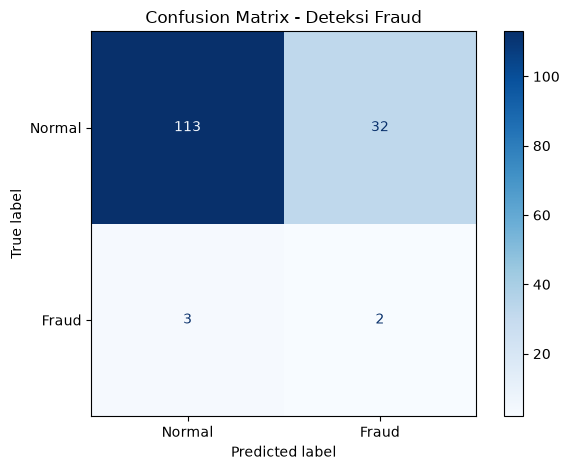

In [5]:
# Import library visualisasi
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Membuat visualisasi confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Fraud']
).plot(cmap='Blues', values_format='d')

# Memberikan judul grafik
plt.title('Confusion Matrix - Deteksi Fraud')

# Mengatur tampilan grafik
plt.tight_layout()

# Menampilkan grafik
plt.show()

**5.3	Tugas 3 — Evaluasi Data Tidak Seimbang**

Bandingkan baseline semua normal dan Decision Tree pada Bagian 4.7. Jelaskan mengapa accuracy tinggi belum tentu menunjukkan kemampuan mendeteksi fraud.

In [6]:
# Import library
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Membuat prediksi baseline
# Semua transaksi diprediksi sebagai normal (0)
baseline = np.zeros(len(y_test), dtype=int)

# Menghitung accuracy baseline
print("Baseline Accuracy:")
print(accuracy_score(y_test, baseline))

# Menampilkan hasil evaluasi baseline
print("\nClassification Report Baseline:")
print(classification_report(
    y_test,
    baseline,
    labels=[0, 1],
    target_names=['Normal', 'Fraud'],
    zero_division=0
))

# Menampilkan hasil evaluasi Decision Tree
print("\nClassification Report Decision Tree:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Normal', 'Fraud'],
    zero_division=0
))

Baseline Accuracy:
0.9666666666666667

Classification Report Baseline:
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.98       145
       Fraud       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150


Classification Report Decision Tree:
              precision    recall  f1-score   support

      Normal       0.97      0.78      0.87       145
       Fraud       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



Visualisasi Perbandingan

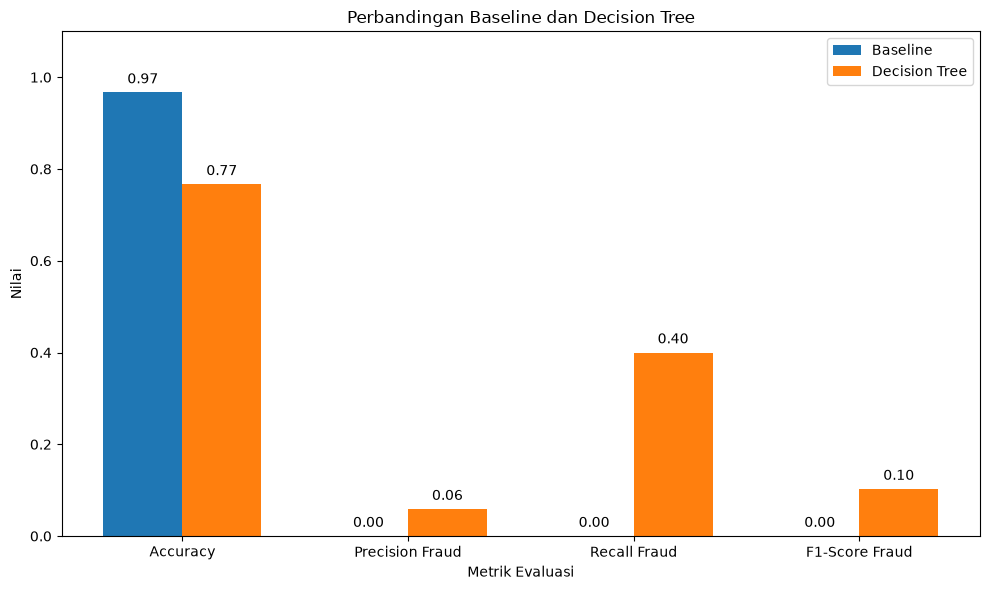

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Data hasil evaluasi
metrik = ['Accuracy', 'Precision Fraud', 'Recall Fraud', 'F1-Score Fraud']

baseline_score = [0.9667, 0, 0, 0]
decision_tree_score = [0.7667, 0.0588, 0.4000, 0.1026]

# Menentukan posisi grafik
x = np.arange(len(metrik))
width = 0.35

# Membuat grafik
plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    baseline_score,
    width,
    label='Baseline'
)

plt.bar(
    x + width/2,
    decision_tree_score,
    width,
    label='Decision Tree'
)

# Memberikan keterangan
plt.title('Perbandingan Baseline dan Decision Tree')
plt.xlabel('Metrik Evaluasi')
plt.ylabel('Nilai')
plt.xticks(x, metrik)
plt.ylim(0, 1.1)
plt.legend()

# Menampilkan nilai pada grafik
for i, value in enumerate(baseline_score):
    plt.text(i - width/2, value + 0.02,
             f'{value:.2f}', ha='center')

for i, value in enumerate(decision_tree_score):
    plt.text(i + width/2, value + 0.02,
             f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

Visualisasi Confusion Matrix Kedua Model

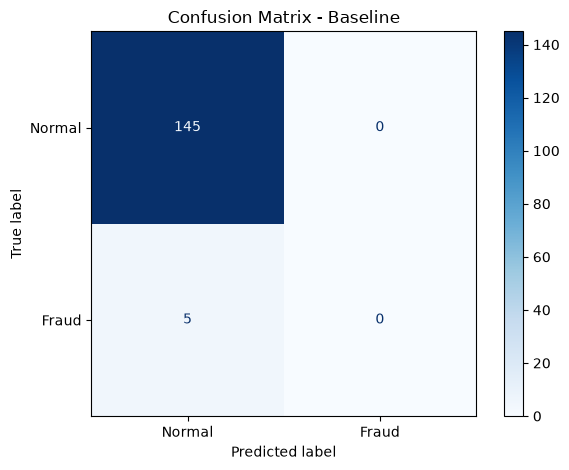

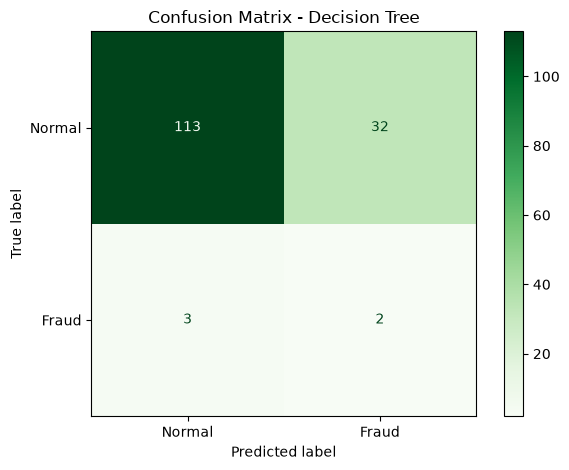

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix baseline
cm_baseline = confusion_matrix(
    y_test,
    baseline,
    labels=[0, 1]
)

# Confusion matrix Decision Tree
cm_tree = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

# Visualisasi baseline
ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=['Normal', 'Fraud']
).plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Baseline')
plt.tight_layout()
plt.show()

# Visualisasi Decision Tree
ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=['Normal', 'Fraud']
).plot(cmap='Greens', values_format='d')

plt.title('Confusion Matrix - Decision Tree')
plt.tight_layout()
plt.show()

Mengapa Accuracy Tinggi Belum Tentu Menunjukkan Kemampuan Mendeteksi Fraud?

Accuracy yang tinggi belum tentu menunjukkan bahwa model memiliki kemampuan mendeteksi fraud yang baik karena jumlah data normal dan fraud dalam dataset tidak seimbang.

Pada praktikum ini, terdapat 500 data transaksi yang terdiri dari 484 transaksi normal dan hanya 16 transaksi fraud. Pada data uji, terdapat 145 transaksi normal dan hanya 5 transaksi fraud.

Ketika model baseline selalu memprediksi semua transaksi sebagai normal, model tetap mendapatkan accuracy sebesar 96,67% karena sebagian besar data memang merupakan transaksi normal. Namun, model tersebut tidak berhasil mendeteksi satu pun transaksi fraud.

Berbeda dengan baseline, Decision Tree memiliki accuracy sebesar 76,67%, tetapi mampu mendeteksi 2 dari 5 transaksi fraud. Hal ini menunjukkan bahwa meskipun accuracy lebih rendah, Decision Tree masih memiliki kemampuan untuk menemukan transaksi penipuan.

Oleh karena itu, untuk kasus deteksi fraud, penilaian model tidak cukup hanya menggunakan accuracy. Metrik seperti precision, recall, dan F1-score juga perlu diperhatikan agar kemampuan model dalam mendeteksi transaksi fraud dapat diketahui dengan lebih jelas.

**5.4	Tugas 4 — Eksperimen dan Rekomendaasi**

Uji empat threshold pada Bagian 4.8. Buat tabel precision dan recall, pilih threshold untuk skenario biaya FN lebih tinggi daripada FP, dan berikan argumentasi berbasis hasil.

pengujian dan visualisasi threshold

Tabel Hasil Pengujian Threshold
 Threshold Precision Recall
       0.2     0.059  0.400
       0.4     0.059  0.400
       0.5     0.059  0.400
       0.7     0.056  0.200


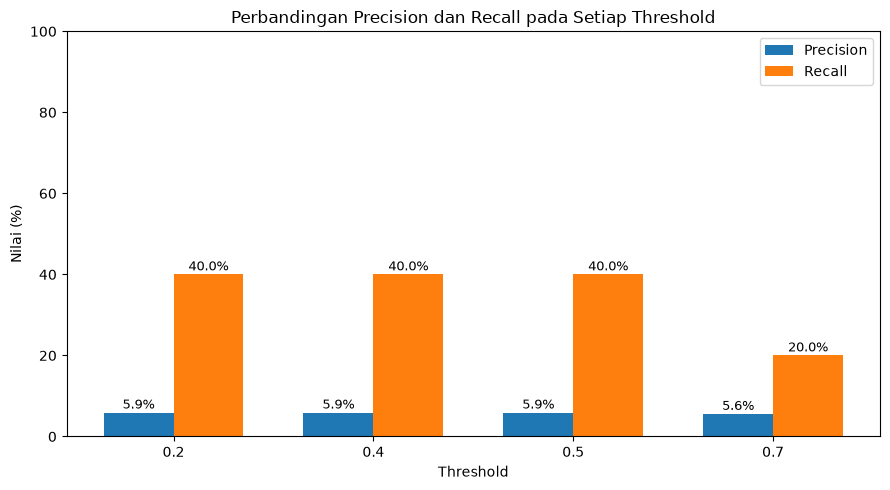

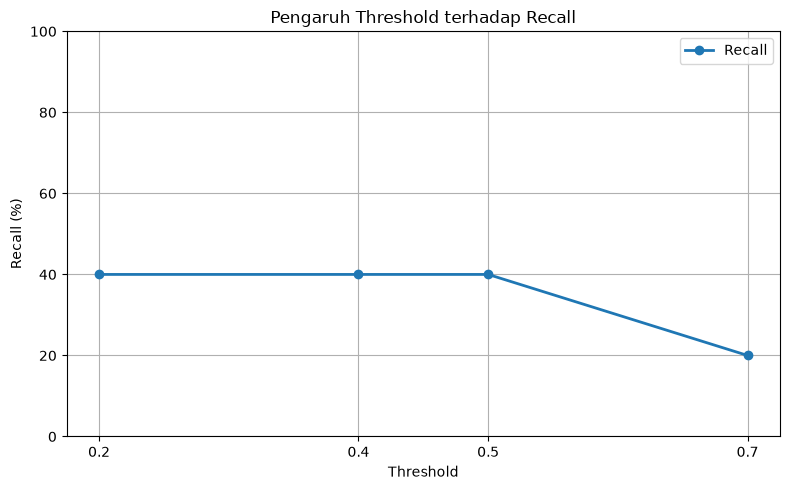

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_score, recall_score

# Mengambil probabilitas prediksi kelas Fraud (kelas 1)
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

# Empat threshold yang akan diuji
thresholds = [0.2, 0.4, 0.5, 0.7]

# Menyimpan hasil pengujian
hasil = []

for threshold in thresholds:
    # Mengubah probabilitas menjadi prediksi kelas
    pred = (y_prob >= threshold).astype(int)

    # Menghitung precision dan recall
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)

    hasil.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall
    })

# Membuat tabel hasil
df_threshold = pd.DataFrame(hasil)

print("Tabel Hasil Pengujian Threshold")
print(df_threshold.to_string(
    index=False,
    formatters={
        'Precision': '{:.3f}'.format,
        'Recall': '{:.3f}'.format
    }
))

# Mengubah nilai menjadi persen untuk visualisasi
precision = df_threshold['Precision'] * 100
recall = df_threshold['Recall'] * 100

# Visualisasi perbandingan Precision dan Recall
x = np.arange(len(thresholds))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, precision, width, label='Precision')
plt.bar(x + width/2, recall, width, label='Recall')

plt.title('Perbandingan Precision dan Recall pada Setiap Threshold')
plt.xlabel('Threshold')
plt.ylabel('Nilai (%)')
plt.xticks(x, thresholds)
plt.ylim(0, 100)
plt.legend()

# Menampilkan angka di atas batang
for i, nilai in enumerate(precision):
    plt.text(i - width/2, nilai + 1, f'{nilai:.1f}%',
             ha='center', fontsize=9)

for i, nilai in enumerate(recall):
    plt.text(i + width/2, nilai + 1, f'{nilai:.1f}%',
             ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# Visualisasi perubahan Recall berdasarkan Threshold
plt.figure(figsize=(8, 5))

plt.plot(thresholds, recall, marker='o',
         linewidth=2, label='Recall')

plt.title('Pengaruh Threshold terhadap Recall')
plt.xlabel('Threshold')
plt.ylabel('Recall (%)')
plt.xticks(thresholds)
plt.ylim(0, 100)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()
